# m14 - Satellite Imagery: Does Sentinel-2 Add to the Physical Drivers?

**Question.** The 14 physical drivers (climate, soil, terrain) explain about 82 % of the variance of the 1 km GAEZ index
(m01). Sentinel-2 (2020-2024, `scripts/preprocessing/11_sentinel2_cell_features.ipynb`) observes the land surface itself:
vegetation greenness and moisture, bare and built-up land. Does it add skill, and does a convolutional network that sees each
cell's image patch do better than per-cell statistics?

Sentinel-2 shows current land cover and land use, which GAEZ partly reflects (its 1 km product leaves out land it does not
count as cropland), so a gain here means the imagery carries information the drivers lack, not that a satellite sees
suitability directly.

**Setup.** The 9,129 cells with a 1 km target and the same pixel-grouped folds everywhere (5 folds, 1 repeat).

1. **Per-cell statistics, tree models** (ExtraTrees, HistGB): the 14 drivers, the 23 Sentinel-2 statistics alone, and both.
2. **Image patches, neural networks** on the GPU: an MLP on the 14 drivers, a small CNN on the 25 x 25 patches (five-year
   composite of 9 bands plus a validity channel), and a fusion network with both branches.

In [1]:
import torch  # noqa: F401  - keep first (see exp_lib docstring)
import sys
import time
from pathlib import Path

# Make exp_lib importable no matter where the notebook is launched from.
HERE = next(p for p in (Path.cwd(), Path.cwd() / "scripts" / "modeling") if (p / "exp_lib.py").exists())
sys.path.insert(0, str(HERE))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

import exp_lib as E
import exp_torch as T
from threadpoolctl import threadpool_limits

threadpool_limits(E.N_JOBS)   # BLAS/OpenMP in this kernel stay within the same CPU budget as the worker pool
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 160)
DEVICE = T.DEVICE
print("device:", DEVICE, torch.cuda.get_device_name(0) if DEVICE == "cuda" else "")

device: cuda NVIDIA GeForce RTX 5060


In [2]:
df = E.load_table()
S2 = E.FEATURE_GROUPS["sentinel2"]
assert all(c in df for c in S2), "run scripts/preprocessing/11_sentinel2_cell_features.ipynb first"
BASE = E.feature_columns()
targets = {c: df[E.target_col(c)].to_numpy() for c in E.CROPS}
X, Y = df[BASE].to_numpy(float), df[E.gaez_cols()].to_numpy(float)
SPLITS = E.make_splits(df, "pixel", 5, seed=0)      # the folds of every model below
print(f"{len(df)} cells, {len(BASE)} drivers, {len(S2)} Sentinel-2 statistics; "
      f"{int(df[S2].isna().all(axis=1).sum())} cells without any Sentinel-2 pixel")

9129 cells, 14 drivers, 23 Sentinel-2 statistics; 0 cells without any Sentinel-2 pixel


## 1. Per-cell Sentinel-2 statistics with tree models

In [3]:
SETS = {"14 drivers": BASE, "Sentinel-2 only": S2, "drivers + Sentinel-2": BASE + S2}
parts = []
for name, cols in SETS.items():
    r, _ = E.run_grid(df, targets, ["et", "hgb"], [], columns=cols, custom_splits={"pixel": SPLITS}, verbose=False)
    parts.append(r.assign(features=name))
tab_raw = pd.concat(parts, ignore_index=True)
E.save_table(tab_raw, "m14_tabular_raw")
tab = tab_raw.groupby(["features", "model"])["r2"].mean().unstack("model").reindex(list(SETS))
tab.round(3)

model,et,hgb
features,,
14 drivers,0.819,0.805
Sentinel-2 only,0.723,0.708
drivers + Sentinel-2,0.865,0.856


In [4]:
per_crop = tab_raw.pivot_table(index="target", columns=["model", "features"], values="r2").reindex(E.CROPS)
gain = pd.DataFrame({m: per_crop[(m, "drivers + Sentinel-2")] - per_crop[(m, "14 drivers")] for m in ["et", "hgb"]})
gain.columns = ["ExtraTrees gain", "HistGB gain"]
gain["ExtraTrees R2, drivers"] = per_crop[("et", "14 drivers")]
gain["ExtraTrees R2, Sentinel-2 only"] = per_crop[("et", "Sentinel-2 only")]
gain.round(3)

,ExtraTrees gain,HistGB gain,"ExtraTrees R2, drivers","ExtraTrees R2, Sentinel-2 only"
target,,,,
rice,0.039,0.044,0.849,0.775
maize,0.042,0.048,0.804,0.731
cassava,0.043,0.045,0.838,0.739
soybean,0.052,0.078,0.780,0.695
oilpalm,0.046,0.049,0.829,0.710
rubber,0.060,0.056,0.755,0.633
sugarcane,0.044,0.044,0.842,0.762
coffee,0.044,0.048,0.835,0.724
cacao,0.051,0.053,0.809,0.706


## 2. Image patches: CNN and fusion network

Every cell has a 25 x 25 patch per year (4 x 4 block means of its 100 x 100 Sentinel-2 pixels, notebook 11). The five years
are merged into one composite, weighted by the share of cloud-free pixels behind each block. Inputs, patches and targets are
standardised with training-fold statistics only; patches are flipped at random during training (orientation does not matter
for suitability).

In [5]:
P = T.load_patch_composite(df["grid_id"])     # (n, 10, 25, 25): five-year composite + valid share, exp_torch
print("patch tensor:", P.shape, f"{P.nbytes / 1e6:.0f} MB")

patch tensor: (9129, 10, 25, 25) 228 MB


In [6]:
# The networks live in exp_torch (PatchCNN, FusionNet, fit_predict_fusion) so the AI Lab trains exactly the same ones.
VARIANTS = {"MLP, 14 drivers": (False, True), "CNN, image patch": (True, False), "Fusion, patch + drivers": (True, True)}


def fit_predict(variant, tr, te, seed=0):
    use_patch, use_drivers = VARIANTS[variant]
    return T.fit_predict_fusion(P, X, Y, tr, te, use_patch, use_drivers, seed=seed)

In [7]:
deep_oof = {v: np.zeros_like(Y) for v in VARIANTS}
t0 = time.time()
for v in VARIANTS:
    for k, (tr, te) in enumerate(SPLITS):
        deep_oof[v][te] = fit_predict(v, tr, te, seed=k)
    print(f"{v:26s} done after {time.time() - t0:.0f} s", flush=True)
rows = [{"model": v, "crop": c, **E.regression_metrics(Y[:, j], deep_oof[v][:, j])}
        for v in VARIANTS for j, c in enumerate(E.CROPS)]
deep = pd.DataFrame(rows)
E.save_table(deep, "m14_deep_raw")
deep.groupby("model", sort=False)[["r2", "spearman", "rmse"]].mean().round(3)

MLP, 14 drivers            done after 14 s


CNN, image patch           done after 41 s


Fusion, patch + drivers    done after 72 s


,r2,spearman,rmse
model,,,
"MLP, 14 drivers",0.789,0.887,948.852
"CNN, image patch",0.764,0.868,1012.021
"Fusion, patch + drivers",0.869,0.929,741.810


## 3. Everything side by side

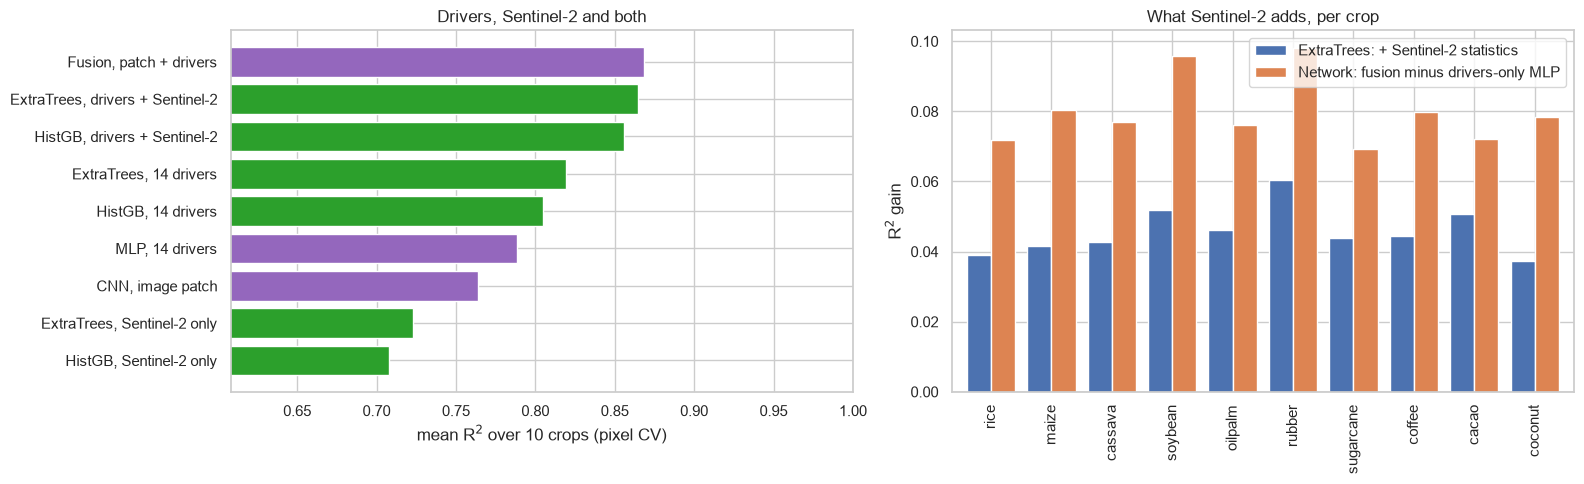

,setting,family,r2,spearman,rmse
4,"HistGB, Sentinel-2 only","trees, per-cell statistics",0.708,0.835,1128.236
1,"ExtraTrees, Sentinel-2 only","trees, per-cell statistics",0.723,0.845,1097.493
7,"CNN, image patch","neural networks, image patches",0.764,0.868,1012.021
6,"MLP, 14 drivers","neural networks, image patches",0.789,0.887,948.852
3,"HistGB, 14 drivers","trees, per-cell statistics",0.805,0.896,909.719
0,"ExtraTrees, 14 drivers","trees, per-cell statistics",0.819,0.901,876.428
5,"HistGB, drivers + Sentinel-2","trees, per-cell statistics",0.856,0.923,779.902
2,"ExtraTrees, drivers + Sentinel-2","trees, per-cell statistics",0.865,0.928,754.997
8,"Fusion, patch + drivers","neural networks, image patches",0.869,0.929,741.810


In [8]:
names = {"et": "ExtraTrees", "hgb": "HistGB"}
trees = (tab_raw.groupby(["model", "features"])[["r2", "spearman", "rmse"]].mean().reset_index()
         .assign(setting=lambda t: t["model"].map(names) + ", " + t["features"], family="trees, per-cell statistics"))
nets = (deep.groupby("model", sort=False)[["r2", "spearman", "rmse"]].mean().reset_index()
        .rename(columns={"model": "setting"}).assign(family="neural networks, image patches"))
summary = pd.concat([trees, nets], ignore_index=True)[["setting", "family", "r2", "spearman", "rmse"]].sort_values("r2")
E.save_table(summary.round(4), "m14_summary")

crop_gain = pd.DataFrame({
    "ExtraTrees: + Sentinel-2 statistics": gain["ExtraTrees gain"],
    "Network: fusion minus drivers-only MLP": deep.pivot(index="crop", columns="model", values="r2").reindex(E.CROPS)
        .pipe(lambda t: t["Fusion, patch + drivers"] - t["MLP, 14 drivers"]),
})
E.save_table(crop_gain.round(4), "m14_gain_by_crop", index=True)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
colors = summary["family"].map({"trees, per-cell statistics": "tab:green", "neural networks, image patches": "tab:purple"})
axes[0].barh(summary["setting"], summary["r2"], color=colors)
axes[0].set(xlabel="mean R$^2$ over 10 crops (pixel CV)", title="Drivers, Sentinel-2 and both", xlim=(max(0, summary["r2"].min() - 0.1), 1))
crop_gain.plot.bar(ax=axes[1], width=0.8)
axes[1].axhline(0, color="black", lw=0.8)
axes[1].set(ylabel="R$^2$ gain", xlabel="", title="What Sentinel-2 adds, per crop")
plt.tight_layout()
E.save_fig(fig, "m14_summary")
plt.show()
summary.round(3)

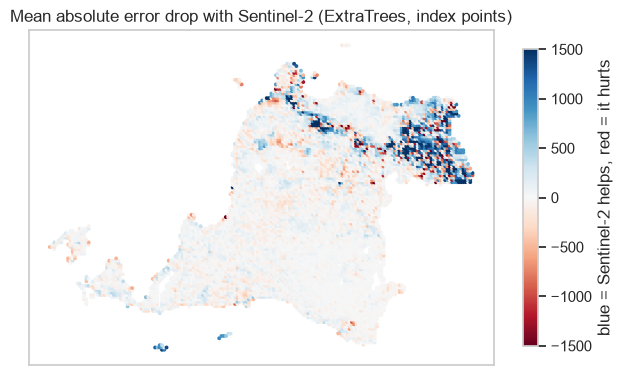

,mean,size
land cover,,
Bare / sparse,-2004.8,2
Mangroves,-111.4,6
Grassland,-20.1,76
Tree cover,11.8,6816
Water,22.2,163
Cropland,103.2,1282
Wetland,119.1,12
Built-up,427.4,772


In [9]:
# Where does the imagery help? Error of the drivers-only model minus error of the drivers + Sentinel-2 model (ExtraTrees).
r_base, o_base = E.run_grid(df, targets, ["et"], [], columns=BASE, custom_splits={"pixel": SPLITS}, keep_oof=True, verbose=False)
r_both, o_both = E.run_grid(df, targets, ["et"], [], columns=BASE + S2, custom_splits={"pixel": SPLITS}, keep_oof=True, verbose=False)
improve = np.mean([np.abs(o_base[("et", c, "pixel", 0)] - targets[c]) - np.abs(o_both[("et", c, "pixel", 0)] - targets[c])
                   for c in E.CROPS], axis=0)
lc = {10: "Tree cover", 20: "Shrubland", 30: "Grassland", 40: "Cropland", 50: "Built-up", 60: "Bare / sparse",
      80: "Water", 90: "Wetland", 95: "Mangroves"}   # ESA WorldCover codes present in Banten
by_lc = (pd.DataFrame({"land cover": df["landcover_majority"].map(lc).fillna("other"), "error reduction": improve})
         .groupby("land cover")["error reduction"].agg(["mean", "size"]).sort_values("mean"))
fig, ax = plt.subplots(figsize=(7.5, 5.5))
sc = ax.scatter(df["lon"], df["lat"], c=improve, s=3, cmap="RdBu", vmin=-1500, vmax=1500)
ax.set(title="Mean absolute error drop with Sentinel-2 (ExtraTrees, index points)", aspect="equal")
ax.set_xticks([])
ax.set_yticks([])
fig.colorbar(sc, ax=ax, shrink=0.7, label="blue = Sentinel-2 helps, red = it hurts")
E.save_fig(fig, "m14_error_map")
plt.show()
by_lc.round(1)

## Findings

* **Sentinel-2 adds to the physical drivers, for every crop.** ExtraTrees goes from R² 0.82 with the 14 drivers to
  0.87 with the 23 Sentinel-2 statistics added (+0.04 to +0.06 per crop), HistGB from 0.81 to 0.86.
  The imagery alone reaches 0.72: it describes the land well, but less well than the drivers.
* **The fusion network is the best model of the project (R² 0.87).** A CNN on the 25 x 25 image patches alone reaches
  0.76; joined with the drivers it beats the drivers-only MLP by 0.07 to 0.10 per crop and is on par
  with the best tree model (0.865). With imagery in the input, deep learning catches up with the trees.
* **The gain sits where land use matters.** The error drops most in built-up cells (about 430 index points of mean
  absolute error) and on cropland (about 100), hardly at all under tree cover. The 1 km GAEZ reflects current land cover
  and land use (it leaves out land it does not count as cropland), which the physical drivers do not see and a satellite
  does: the gain is that information, not suitability observed from space.